# Immune signatures as an interpretable survival baseline in TCGA-LUAD
**IL181 Molecular Immunology · Assignment 1 (bioinformatics analysis of existing data)**
Alexia Moreanu

**Question.** How much overall-survival signal in lung adenocarcinoma is carried by a handful of
well-characterised immune gene signatures, independent of age and stage, and which immune
processes carry it?

**Why.** This is the biologically grounded baseline for my capstone (re-implementing CATfusion, a
slide + genomics cross-attention survival model, in JAX). A multimodal model is only interesting
if it beats a simple, interpretable baseline, and these signatures are later used to probe what
CATfusion's slide and genomic branches have learned.

**Data.** GDC TCGA-LUAD via UCSC Xena: STAR TPM (log2(TPM+1)), GENCODE v36 probemap,
clinical phenotype (age, AJCC pathologic stage, vital status and follow-up for overall survival). Primary tumours only, one sample per patient.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.stats.multitest import multipletests

import immune_signatures as sig

DATA = "data/"            # folder holding the Xena downloads
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
COLORS = {"cDC1": "#2E6F95", "Cytolytic": "#C8553D", "TLS": "#3C8D5A",
          "MHC-I": "#8E6CB0", "Treg": "#D4A72C"}

## 1. Load and assemble the cohort

In [2]:
# Reading only the 18 signature genes from the 60k-row matrix (cached after the first run)
genes = sorted({g for gs in sig.SIGNATURES.values() for g in gs})
try:
    expr = pd.read_csv(DATA + "luad_signature_genes.tsv", sep="\t", index_col=0)
except FileNotFoundError:
    expr = sig.load_expression(DATA + "TCGA-LUAD.star_tpm.tsv.gz",
                               DATA + "gencode.v36.annotation.gtf.gene.probemap", genes)
    expr.to_csv(DATA + "luad_signature_genes.tsv", sep="\t")

# Overall survival is derived from the clinical file (vital status, days to death / last follow-up).
# If you also download Xena's TCGA-LUAD.survival.tsv.gz, pass its path instead of None.
cohort = sig.load_cohort(expr, None, DATA + "TCGA-LUAD.clinical.tsv.gz")
scores = sig.score_signatures(cohort)
data = cohort[["time", "event", "age", "stage"]].join(scores)
data["time"] = data["time"] / 30.44          # days -> months
data[["age"]] = sig.zscore(data[["age"]])    # HR per SD of age, comparable to the signatures

print(f"Patients: {len(data)}  |  deaths: {data.event.sum()}  |  "
      f"median follow-up: {data.time.median():.1f} months")
print(cohort.stage.value_counts().sort_index().rename('patients by stage').to_string())

Patients: 485  |  deaths: 177  |  median follow-up: 21.4 months
stage
1.0    263
2.0    118
3.0     79
4.0     25


## 2. Do the signatures measure distinct immune processes?
If all five signatures were just "more immune cells", they would be nearly collinear. The
correlation structure tells us whether the tumour microenvironment is better described as
separate axes (priming, killing, organised lymphoid structures, antigen presentation, suppression).

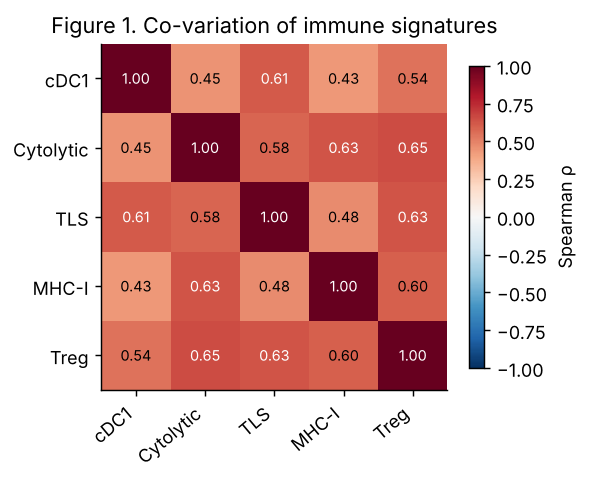

In [3]:
corr = scores.corr(method="spearman")
fig, ax = plt.subplots(figsize=(4.6, 3.9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(5), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(5), corr.index)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Figure 1. Co-variation of immune signatures")
fig.tight_layout(); fig.savefig("figures/fig1_signature_correlation.png", bbox_inches="tight")

## 3. Which immune processes predict survival, independent of age and stage?
One Cox model per signature, each adjusted for age and stage. HR < 1 means higher signature
expression is associated with lower hazard of death (per 1 SD of the score).

In [4]:
rows = []
for name in sig.SIGNATURES:
    tbl = sig.fit_cox(data, [name] + sig.CLINICAL)
    rows.append(tbl.loc[[name]])
adjusted = pd.concat(rows)
adjusted["p_FDR"] = multipletests(adjusted.p, method="fdr_bh")[1]   # 5 signatures tested
adjusted.round(3)

,HR,CI_low,CI_high,p,p_FDR
cDC1,0.834,0.717,0.969,0.018,0.090
Cytolytic,0.946,0.813,1.100,0.468,0.476
TLS,0.875,0.753,1.016,0.081,0.202
MHC-I,1.053,0.913,1.214,0.476,0.476
Treg,0.942,0.817,1.085,0.408,0.476


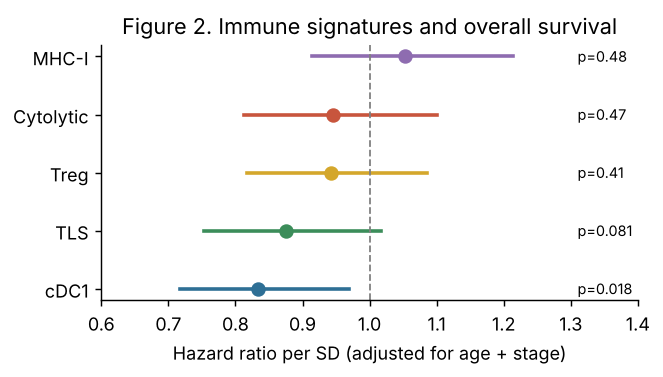

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 3))
order = adjusted.sort_values("HR").index
for y, name in enumerate(order):
    r = adjusted.loc[name]
    ax.plot([r.CI_low, r.CI_high], [y, y], color=COLORS[name], lw=2)
    ax.plot(r.HR, y, "o", color=COLORS[name], ms=7)
    ax.text(1.31, y, f"p={r.p:.2g}", va="center", fontsize=8)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_yticks(range(len(order)), order); ax.set_xlim(0.6, 1.4)
ax.set_xlabel("Hazard ratio per SD (adjusted for age + stage)")
ax.set_title("Figure 2. Immune signatures and overall survival")
fig.tight_layout(); fig.savefig("figures/fig2_forest.png", bbox_inches="tight")

## 4. How much prognostic signal do they add? (cross-validated C-index)
Concordance index on held-out folds (5-fold × 10 repeats). 0.5 = random, 1 = perfect ranking.
This is the same metric CATfusion is evaluated with, so these rows go straight into the
capstone baseline table.

In [6]:
models = {
    "Clinical (age + stage)": sig.CLINICAL,
    **{f"{n} only": [n] for n in sig.SIGNATURES},
    "All immune": list(sig.SIGNATURES),
    "Clinical + cDC1": sig.CLINICAL + ["cDC1"],
    "Clinical + all immune": sig.CLINICAL + list(sig.SIGNATURES),
}
cv = {name: sig.cv_cindex(data, covs) for name, covs in models.items()}
cv_table = pd.DataFrame({"C-index": {k: v.mean() for k, v in cv.items()},
                         "SD": {k: v.std() for k, v in cv.items()}})
cv_table.round(3)

,C-index,SD
Clinical (age + stage),0.672,0.047
cDC1 only,0.572,0.043
Cytolytic only,0.505,0.051
TLS only,0.562,0.048
MHC-I only,0.500,0.040
Treg only,0.538,0.050
All immune,0.562,0.043
Clinical + cDC1,0.677,0.047
Clinical + all immune,0.665,0.049


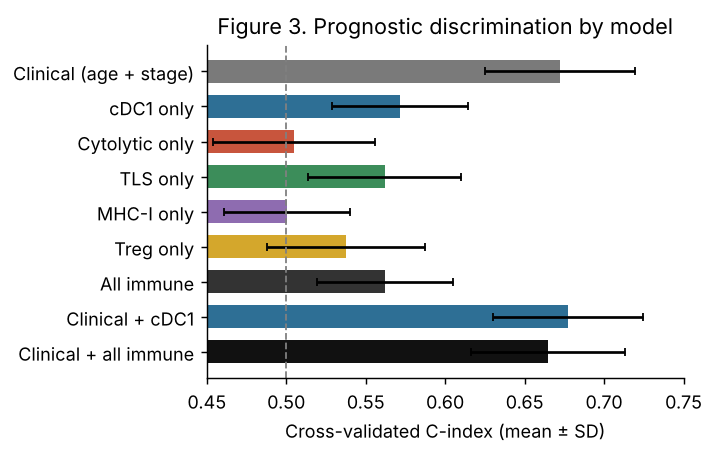

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
names = list(cv)
bar_colors = ["#7A7A7A"] + [COLORS[n] for n in sig.SIGNATURES] + ["#333333", COLORS["cDC1"], "#111111"]
ax.barh(range(len(names)), cv_table["C-index"], xerr=cv_table["SD"], color=bar_colors,
        capsize=2, height=0.65)
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_yticks(range(len(names)), names); ax.invert_yaxis()
ax.set_xlim(0.45, max(0.75, cv_table["C-index"].max() + 0.05))
ax.set_xlabel("Cross-validated C-index (mean ± SD)")
ax.set_title("Figure 3. Prognostic discrimination by model")
fig.tight_layout(); fig.savefig("figures/fig3_cindex.png", bbox_inches="tight")

## 5. Kaplan–Meier view of the strongest signature
Median split, for intuition only (the Cox models above use the continuous score).

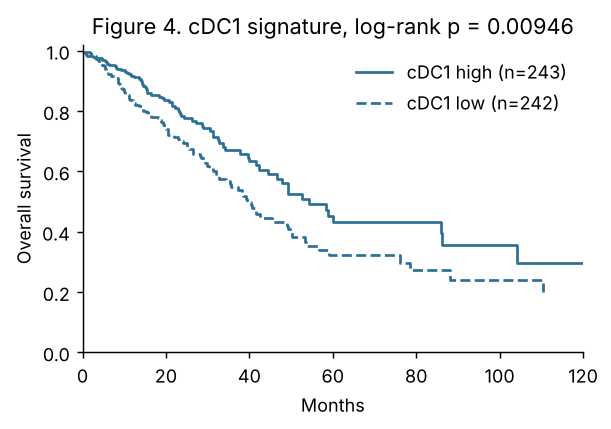

In [8]:
best = adjusted.p.idxmin()
high = data[best] >= data[best].median()

fig, ax = plt.subplots(figsize=(4.8, 3.4))
for mask, label, ls in [(high, "high", "-"), (~high, "low", "--")]:
    sf = SurvfuncRight(data.time[mask], data.event[mask])
    ax.step(sf.surv_times, sf.surv_prob, where="post", color=COLORS[best], ls=ls,
            label=f"{best} {label} (n={mask.sum()})")
chi2, p = survdiff(data.time, data.event, high.astype(int))
ax.set_xlabel("Months"); ax.set_ylabel("Overall survival"); ax.set_ylim(0, 1.02)
ax.set_xlim(0, 120); ax.legend(frameon=False)
ax.set_title(f"Figure 4. {best} signature, log-rank p = {p:.3g}")
fig.tight_layout(); fig.savefig("figures/fig4_km.png", bbox_inches="tight")

## 6. Robustness check: proportional hazards
The Cox model assumes a constant hazard ratio over time. Schoenfeld-residual style check:
correlation between each covariate's residual and event time in the combined model.

In [9]:
from scipy.stats import spearmanr
from statsmodels.duration.hazard_regression import PHReg

covs = sig.CLINICAL + list(sig.SIGNATURES)
fit = PHReg(data.time, data[covs], status=data.event, ties="efron").fit()
died = data.event.to_numpy() == 1
resid = pd.DataFrame(fit.schoenfeld_residuals[died], columns=covs)
ph = pd.DataFrame({c: spearmanr(resid[c], data.time[died]) for c in covs}, index=["rho", "p"]).T
ph.round(3)

,rho,p
age,0.014,0.851
stage,-0.001,0.990
cDC1,0.101,0.182
Cytolytic,0.017,0.827
TLS,0.105,0.164
MHC-I,0.107,0.156
Treg,0.060,0.424


## 7. Hand-off to the capstone
Saved: per-patient signature scores (`luad_immune_scores.tsv`) keyed by TCGA patient barcode.
In the capstone these are (1) the interpretable baseline row in the results table and
(2) the probe for interpretability: correlate CATfusion's full-model and slide-only risk
scores with each signature.

In [10]:
scores.to_csv("results/luad_immune_scores.tsv", sep="\t")
adjusted.round(4).to_csv("results/luad_cox_adjusted.tsv", sep="\t")
cv_table.round(4).to_csv("results/luad_cindex.tsv", sep="\t")